# Text Clustering Using Word2Vec

## Data Collection

*The Data we will be using for this analysis is* ***20 Newsgroups*** *and this Dataset is publicly vaialable on [20 NewsGroups](http://qwone.com/~jason/20Newsgroups/). Download the file and put it on your present working directory or else directly get the datasets using SKLearn Dataset.*

## Importing Dependencies

In [0]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show all columns when looking at dataframe
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook
import matplotlib
import nltk

## Importing Data

*If you are on a unix based system wget, else just download and put it on your current working directory.*

In [2]:
# Downloading the Dataset
!wget http://qwone.com/~jason/20Newsgroups/20news-19997.tar.gz

--2019-09-06 05:05:44--  http://qwone.com/~jason/20Newsgroups/20news-19997.tar.gz
Resolving qwone.com (qwone.com)... 108.20.201.166
Connecting to qwone.com (qwone.com)|108.20.201.166|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 17332201 (17M) [application/x-gzip]
Saving to: ‘20news-19997.tar.gz’

20news-19997.tar.gz 100%[===================>]  16.53M  6.28MB/s    in 2.6s    

2019-09-06 05:05:47 (6.28 MB/s) - ‘20news-19997.tar.gz’ saved [17332201/17332201]



In [3]:
# Unzipping the Zip File
!tar xvzf 20news-19997.tar.gz

20_newsgroups/
20_newsgroups/alt.atheism/
20_newsgroups/alt.atheism/53366
20_newsgroups/alt.atheism/53367
20_newsgroups/alt.atheism/51247
20_newsgroups/alt.atheism/51248
20_newsgroups/alt.atheism/51249
20_newsgroups/alt.atheism/51250
20_newsgroups/alt.atheism/51251
20_newsgroups/alt.atheism/51252
20_newsgroups/alt.atheism/51253
20_newsgroups/alt.atheism/51254
20_newsgroups/alt.atheism/51255
20_newsgroups/alt.atheism/53070
20_newsgroups/alt.atheism/53071
20_newsgroups/alt.atheism/53072
20_newsgroups/alt.atheism/53090
20_newsgroups/alt.atheism/53134
20_newsgroups/alt.atheism/53135
20_newsgroups/alt.atheism/53136
20_newsgroups/alt.atheism/53137
20_newsgroups/alt.atheism/53138
20_newsgroups/alt.atheism/53139
20_newsgroups/alt.atheism/53140
20_newsgroups/alt.atheism/53141
20_newsgroups/alt.atheism/53142
20_newsgroups/alt.atheism/54125
20_newsgroups/alt.atheism/53213
20_newsgroups/alt.atheism/53214
20_newsgroups/alt.atheism/53215
20_newsgroups/alt.atheism/53216
20_newsgroups/alt.atheism/5321

## Data Description

*The 20 Newsgroups data set is a collection of approximately 20,000 newsgroup documents, partitioned (nearly) evenly across 20 different newsgroups. To the best of my knowledge, it was originally collected by Ken Lang, probably for his Newsweeder: Learning to filter netnews paper, though he does not explicitly mention this collection. The 20 newsgroups collection has become a popular data set for experiments in text applications of machine learning techniques, such as text classification and text clustering.*

This is a list of the 20 newsgroups:

- comp.graphics
- comp.os.ms-windows.misc
- comp.sys.ibm.pc.hardware
- comp.sys.mac.hardware
- comp.windows.x rec.autos
- rec.motorcycles
- rec.sport.baseball
- rec.sport.hockey sci.crypt
- sci.electronics
- sci.med
- sci.space
- misc.forsale talk.politics.misc
- talk.politics.guns
- talk.politics.mideast talk.religion.misc
- alt.atheism
- soc.religion.christian

These Categories can be sub clustered in to below 6 Categories

![Cluster](https://i.ibb.co/LkZbj55/Screenshot-85.png)

- Computer Technologies
- Automotives and Sports
- Science
- Misc
- Politics
- Religion

*We will cluster around these 6 categories.*

In [4]:
!dir /content/20_newsgroups

alt.atheism		  rec.autos	      sci.space
comp.graphics		  rec.motorcycles     soc.religion.christian
comp.os.ms-windows.misc   rec.sport.baseball  talk.politics.guns
comp.sys.ibm.pc.hardware  rec.sport.hockey    talk.politics.mideast
comp.sys.mac.hardware	  sci.crypt	      talk.politics.misc
comp.windows.x		  sci.electronics     talk.religion.misc
misc.forsale		  sci.med


In [0]:
text= []
label= []
import os
import codecs
for path, subdirs, files in os.walk(r'/content/20_newsgroups'):
  for filename in files:
    f = os.path.join(path, filename)
    with codecs.open(f, 'r', encoding='utf-8', errors='ignore') as fdata:
      text.append(fdata.read())
    label.append(str(path).split("20_newsgroups/",1)[1])

In [0]:
df= pd.DataFrame({"text": text, "label": label})

In [7]:
df.head()

,text,label
0,Xref: cantaloupe.srv.cs.cmu.edu comp.sys.mac.h...,comp.sys.mac.hardware
1,Xref: cantaloupe.srv.cs.cmu.edu comp.sys.mac.g...,comp.sys.mac.hardware
2,Xref: cantaloupe.srv.cs.cmu.edu comp.sys.mac.h...,comp.sys.mac.hardware
3,Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv....,comp.sys.mac.hardware
4,Newsgroups: comp.sys.mac.hardware\nPath: canta...,comp.sys.mac.hardware


## Data Cleaning

### Removing Header

In [8]:
print(df.text[0])

Xref: cantaloupe.srv.cs.cmu.edu comp.sys.mac.hardware:52001 comp.sys.mac.programmer:58219 comp.sys.mac.misc:43439
Path: cantaloupe.srv.cs.cmu.edu!crabapple.srv.cs.cmu.edu!fs7.ece.cmu.edu!europa.eng.gtefsd.com!howland.reston.ans.net!usc!sol.ctr.columbia.edu!hamblin.math.byu.edu!yvax.byu.edu!cunyvm!psuvm!auvm!br4416a
Newsgroups: comp.sys.mac.hardware,comp.sys.mac.programmer,comp.sys.mac.misc
Subject: Computer repairs
Message-ID: <93110.231504BR4416A@auvm.american.edu>
From: <BR4416A@auvm.american.edu>
Date: Tue, 20 Apr 1993 23:15:03 EDT
Organization: The American University - University Computing Center
Lines: 9

Does anyone out there know where some one can become educated in the art of
repairing Macintosh computers?  Also, how does one gain the prestige of being
refered to as a Authorized Apple Service person?  Has anyone out there actually
done any of this or maybe even know someone who did.  I would appreciate any
and all comments on this subject.

-----------------------------------

In [9]:
print(df.text[0].partition('\n\n')[2])

Does anyone out there know where some one can become educated in the art of
repairing Macintosh computers?  Also, how does one gain the prestige of being
refered to as a Authorized Apple Service person?  Has anyone out there actually
done any of this or maybe even know someone who did.  I would appreciate any
and all comments on this subject.

-------------------------------------------------------------------------------
Ben Roy--------internet<br4416a@american.edu>---------PCS(poor college student)
-------------------------------------------------------------------------------



In [0]:
df.text= df.text.apply(lambda x: x.partition('\n\n')[2])

### Removing Footer

In [0]:
def remove_footer(text):
  lines = text.strip().split('\n')
  for line_num in range(len(lines) - 1, -1, -1):
    line = lines[line_num]
    if line.strip().strip('-') == '':
      break
  if line_num > 0:
    return '\n'.join(lines[:line_num])
  else:
    return text

In [12]:
print(df.text[2])

jacob@plasma2.ssl.berkeley.edu (nga throgaw shaygiy) writes:
: 
: Excuse me if this is a frequent question, I checked in
: several FAQs but couldn't really find anything.

You are excused... the answer varies from Mac to Mac so it would be
a complex answer in the FAQ.
: 
: I have a IIsi with the standard 5 meg memory and I want
: (need) to add additional memory.  But I'm on a budget.
: I really don't need more than 10 meg max, so what is
: the best (performance wise) and most economical way
: to do this?  Someone told me that I should only use
: SIMMs of the same amount of memory, that is 4 1 meg,
: 4 2 meg, etc.  What if I just wanted to buy just 1 4 meg
: and use the rest of what I already have?  The manual
: hasn't been very helpful with this.
: 
The si uses a 32 bit wide data bus and therefore you must use 4 8-bit
wide simms.  Sorry, but no short cuts here.

: Thanks.

You're quite welcome.
: 
Greg.

--
My words, not Motorola's.   * ______ *    EQUAL rights NOT special rights     


In [13]:
print(remove_footer(df.text[2]))

jacob@plasma2.ssl.berkeley.edu (nga throgaw shaygiy) writes:
: 
: Excuse me if this is a frequent question, I checked in
: several FAQs but couldn't really find anything.

You are excused... the answer varies from Mac to Mac so it would be
a complex answer in the FAQ.
: 
: I have a IIsi with the standard 5 meg memory and I want
: (need) to add additional memory.  But I'm on a budget.
: I really don't need more than 10 meg max, so what is
: the best (performance wise) and most economical way
: to do this?  Someone told me that I should only use
: SIMMs of the same amount of memory, that is 4 1 meg,
: 4 2 meg, etc.  What if I just wanted to buy just 1 4 meg
: and use the rest of what I already have?  The manual
: hasn't been very helpful with this.
: 
The si uses a 32 bit wide data bus and therefore you must use 4 8-bit
wide simms.  Sorry, but no short cuts here.

: Thanks.

You're quite welcome.
: 
Greg.



In [0]:
df.text= df.text.apply(remove_footer)

### Remove quoting

In [0]:
import re
quote_re= re.compile(r'(writes in|writes:|wrote:|says:|said:'
                       r'|^In article|^Quoted from|^\||^>)')
def remove_quoting(text):
    good_lines = [line for line in text.split('\n')
                  if not quote_re.search(line)]
    return '\n'.join(good_lines)

In [16]:
print(df.text[0])

Does anyone out there know where some one can become educated in the art of
repairing Macintosh computers?  Also, how does one gain the prestige of being
refered to as a Authorized Apple Service person?  Has anyone out there actually
done any of this or maybe even know someone who did.  I would appreciate any
and all comments on this subject.

-------------------------------------------------------------------------------
Ben Roy--------internet<br4416a@american.edu>---------PCS(poor college student)


In [17]:
print(remove_quoting(df.text[0]))

Does anyone out there know where some one can become educated in the art of
repairing Macintosh computers?  Also, how does one gain the prestige of being
refered to as a Authorized Apple Service person?  Has anyone out there actually
done any of this or maybe even know someone who did.  I would appreciate any
and all comments on this subject.

-------------------------------------------------------------------------------
Ben Roy--------internet<br4416a@american.edu>---------PCS(poor college student)


In [0]:
df.text= df.text.apply(remove_quoting)

### Remving Email ID's

In [0]:
df.text= df.text.str.replace(r'\S*@\S*\s?', "")

### Cleaning

In [0]:
import string
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords 
stop_words = set(stopwords.words('english'))

def clean_text(text):
    # lower text
    text = text.lower()

    # remove puncutation
    text = text.translate(str.maketrans(' ', ' ', string.punctuation))

    # tokenize_text
    text = [word for word in word_tokenize(text)]
    
    # removing Stopwords
    text= [w for w in text if not w in stop_words] 

    # remove words that contain numbers
    text = [word for word in text if not any(c.isdigit() for c in word)]
    
    # remove empty tokens
    text = [t for t in text if len(t) > 0]

    # remove words with only one letter
    text = [t for t in text if len(t) > 1]

    # join all
    text = " ".join(text)
    return(text)

In [0]:
df['clean_text']= df.text.apply(clean_text)

## Data Preprocessing

<h3>TfidfVectorizer</h3>

In [24]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(min_df = 10, max_features=5000)
X1 = vectorizer.fit_transform(df.clean_text)
word_features = vectorizer.get_feature_names()
print("Faetures Length:", len(word_features))
print("Features: ")
word_features[:20]

Faetures Length: 5000
Features: 


['aa',
 'aaron',
 'ab',
 'abc',
 'ability',
 'able',
 'abortion',
 'abortions',
 'abs',
 'absence',
 'absolute',
 'absolutely',
 'abstract',
 'absurd',
 'abuse',
 'ac',
 'academic',
 'acceleration',
 'accelerator',
 'accept']

<h3>CountVectorizer</h3>

In [25]:
from sklearn.feature_extraction.text import CountVectorizer
vectorizer = CountVectorizer(min_df = 10, max_features=5000)
X2 = vectorizer.fit_transform(df.clean_text)
word_features = vectorizer.get_feature_names()
print("Faetures Length:", len(word_features))
print("Features: ")
word_features[:20]

Faetures Length: 5000
Features: 


['aa',
 'aaron',
 'ab',
 'abc',
 'ability',
 'able',
 'abortion',
 'abortions',
 'abs',
 'absence',
 'absolute',
 'absolutely',
 'abstract',
 'absurd',
 'abuse',
 'ac',
 'academic',
 'acceleration',
 'accelerator',
 'accept']

## K-Means Clustering

*Fitting with Default number of cluster that is 8*

X1 ---> TfidfVectorizer

X2 ---> CountVectorizer

### TFIDFVectorizer

In [0]:
from sklearn.cluster import KMeans
kmeans = KMeans()
kmeans.fit(X1.toarray())
common_words = kmeans.cluster_centers_.argsort()[:,-1:-26:-1]
for num, centroid in enumerate(common_words):
    print(f"Cluster {str(num + 1)}" + ' : ' + ', '.join(word_features[word] for word in centroid))

Cluster 1 : would, people, dont, one, think, like, know, get, us, right, time, even, well, government, see, could, im, say, much, good, make, way, said, many, really
Cluster 2 : drive, scsi, drives, hard, ide, disk, controller, floppy, mac, system, hd, tape, meg, external, software, would, problem, use, card, internal, bus, one, dos, thanks, mb
Cluster 3 : use, card, system, would, get, one, chip, key, im, using, like, need, monitor, know, used, problem, software, work, computer, also, anyone, data, program, dont, could
Cluster 4 : one, new, like, also, would, get, good, well, think, car, know, first, im, dont, time, used, may, much, could, us, back, got, article, years, anyone
Cluster 5 : god, jesus, bible, christ, believe, one, faith, christian, christians, would, people, sin, gods, church, us, say, life, think, dont, love, christianity, know, heaven, lord, must
Cluster 6 : windows, file, dos, files, window, program, version, use, using, problem, get, run, thanks, running, system, di

*Lets build a elbow chart*

In [0]:
# Calculating Within clusters sum of Squares (WCSS)
wcss = []
for i in range(1,20):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=0)
    kmeans.fit(X1)
    wcss.append(kmeans.inertia_)

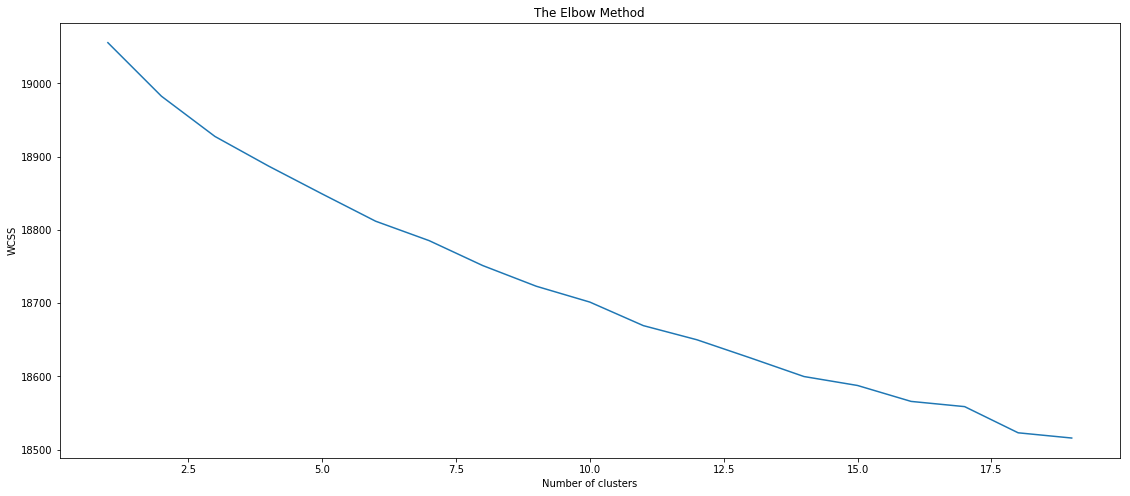

In [0]:
plt.figure(figsize=(19, 8))
plt.plot(range(1,20),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.savefig('elbow.png')
plt.show()

*At the very beginning breaked down the 20 news groups to 6 Newsgroups. Lets Cluster for 6 Newsgroups.*

In [0]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters= 6) 
kmeans.fit(X1.toarray())
common_words = kmeans.cluster_centers_.argsort()[:,-1:-26:-1]
for num, centroid in enumerate(common_words):
    print(f"Cluster {str(num+1)}" + ' : ' + ', '.join(word_features[word] for word in centroid))

Cluster 1 : one, new, like, also, get, use, would, good, im, used, well, know, dont, think, time, first, may, ive, much, could, got, car, two, anyone, problem
Cluster 2 : would, people, dont, one, think, like, get, know, us, could, even, time, well, right, government, im, see, make, good, much, say, way, also, really, many
Cluster 3 : god, jesus, bible, christ, believe, one, faith, christian, christians, people, would, sin, gods, church, us, say, dont, life, think, know, love, christianity, lord, heaven, truth
Cluster 4 : windows, file, program, files, dos, window, use, using, version, problem, running, get, server, run, system, thanks, know, image, would, help, application, format, display, anyone, like
Cluster 5 : thanks, please, email, anyone, drive, know, card, would, im, advance, hi, looking, help, like, scsi, get, one, mac, monitor, info, could, interested, system, need, use
Cluster 6 : game, team, games, year, hockey, players, last, season, baseball, play, league, would, teams, 

### CountVectorizer

In [0]:
from sklearn.cluster import KMeans
kmeans = KMeans()
kmeans.fit(X2.toarray())
common_words = kmeans.cluster_centers_.argsort()[:,-1:-26:-1]
for num, centroid in enumerate(common_words):
    print(f"Cluster {str(num + 1)}" + ' : ' + ', '.join(word_features[word] for word in centroid))

Cluster 1 : would, one, like, people, dont, know, get, also, think, time, use, could, im, good, well, new, may, us, even, much, see, first, two, way, make
Cluster 2 : maxaxaxaxaxaxaxaxaxaxaxaxaxaxax, part, end, good, well, might, number, things, available, program, systems, evidence, seem, window, yet, next, bad, else, disk, idea, thought, worth, drivers, black, due
Cluster 3 : jpeg, image, file, gif, images, format, version, quality, files, free, color, see, programs, use, available, software, also, may, get, dont, display, note, viewer, much, conversion
Cluster 4 : db, byte, bits, push, pop, one, si, inc, al, loop, offset, call, higher, gas, lower, bit, east, data, west, left, place, right, stuff, add, moving
Cluster 5 : widget, application, resource, visual, value, type, converter, xt, widgets, data, set, file, use, string, one, may, used, return, top, list, display, window, shell, resources, default
Cluster 6 : file, gun, control, bill, mr, states, firearms, united, house, handgun,

*Lets build a elbow chart*

In [0]:
# Calculating Within clusters sum of Squares (WCSS)
wcss = []
for i in range(1,20):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=0)
    kmeans.fit(X2)
    wcss.append(kmeans.inertia_)

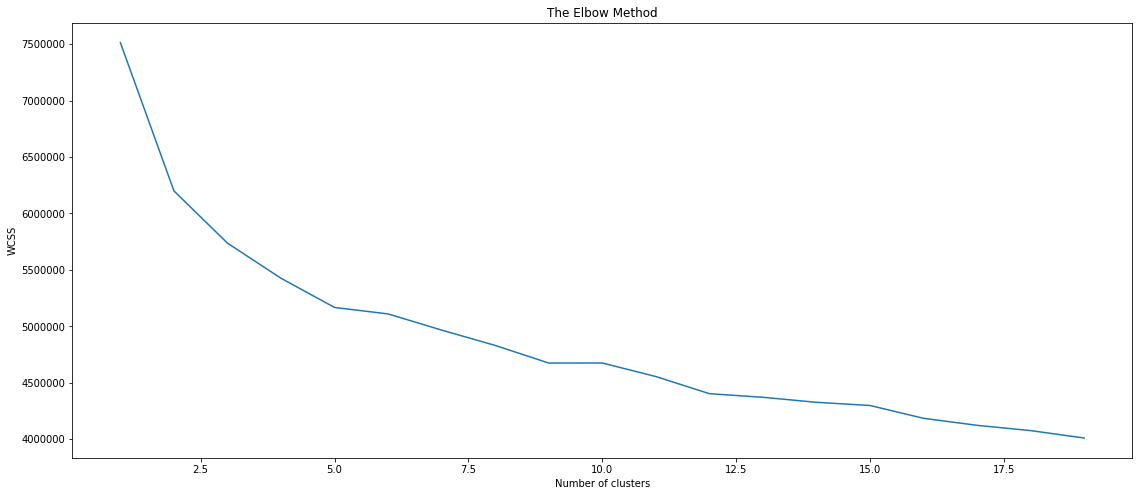

In [0]:
plt.figure(figsize=(19, 8))
plt.plot(range(1,20),wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.savefig('elbow.png')
plt.show()

*We can see multiple elbows here lets try selecting the value of K in KMeans using Silhouette Analysis.*

### Selecting the number of Clusters with Silhouette Analysis on KMeans Clustering in Scikit-learn

*The silhouette analysis measures how well an observation is clustered and it estimates the average distance between clusters. The silhouette plot displays a measure of how close each point in one cluster is to points in the neighboring clusters.*

In [26]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score

X= X2.toarray()

range_n_clusters = [5, 6, 7, 8, 10]

for n_clusters in range_n_clusters:

    # Initialize the clusterer with n_clusters value and a random generator
    # seed of 10 for reproducibility.
    clusterer = KMeans(n_clusters=n_clusters, random_state=10)
    cluster_labels = clusterer.fit_predict(X)

    # The silhouette_score gives the average value for all the samples.
    # This gives a perspective into the density and separation of the formed
    # clusters
    silhouette_avg = silhouette_score(X, cluster_labels)
    print("For n_clusters =", n_clusters,
          "The average silhouette_score is :", silhouette_avg)

For n_clusters = 5 The average silhouette_score is : 0.9062681438414611
For n_clusters = 6 The average silhouette_score is : 0.9162013787664327
For n_clusters = 7 The average silhouette_score is : 0.924524345910879
For n_clusters = 8 The average silhouette_score is : 0.7614572168518936
For n_clusters = 10 The average silhouette_score is : 0.781244767527463


*average silhouette_score for n_clusters 7 is highest.*

*At the very beginning breaked down the 20 news groups to 6 Newsgroups. Lets Cluster for 6 Newsgroups. using CountVectorizer*

In [27]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters= 6) 
kmeans.fit(X2.toarray())
common_words = kmeans.cluster_centers_.argsort()[:,-1:-26:-1]
for num, centroid in enumerate(common_words):
    print(f"Cluster {str(num+1)}" + ' : ' + ', '.join(word_features[word] for word in centroid))

Cluster 1 : one, people, would, also, god, us, may, new, time, use, first, two, many, like, even, db, system, well, said, information, space, know, see, dont, get
Cluster 2 : would, one, like, dont, people, know, get, think, also, time, im, use, could, good, well, even, new, much, may, see, us, make, way, first, two
Cluster 3 : maxaxaxaxaxaxaxaxaxaxaxaxaxaxax, part, end, good, well, might, number, things, available, program, systems, evidence, seem, window, yet, next, bad, else, disk, idea, thought, worth, drivers, black, due
Cluster 4 : jpeg, image, file, gif, images, format, version, quality, files, free, color, see, programs, use, available, software, also, may, get, dont, display, note, viewer, much, conversion
Cluster 5 : file, use, available, also, system, image, program, data, information, one, files, get, software, may, server, version, ftp, subject, anonymous, email, window, entry, graphics, new, set
Cluster 6 : mr, know, said, president, dont, think, going, one, people, us, w

## Clustering Using NLTK clusterer with cosine distance

In [0]:
from nltk.cluster import KMeansClusterer
from sklearn import cluster
from sklearn import metrics

## Word2Vec

In [0]:
from gensim.models import Word2Vec
Bigger_list= [word_tokenize(w) for w in df.clean_text.to_list()]
Model= Word2Vec(Bigger_list, min_count=15, size=5000, sg=0) # Continuous Bag of Words (CBOW) Model, sg=0

In [0]:
# Function to average all word vectors in a paragraph
def featureVecMethod(words, model, num_features):
    # Pre-initialising empty numpy array for speed
    featureVec = np.zeros(num_features,dtype="float32")
    nwords = 0
    #Converting Index2Word which is a list to a set for better speed in the execution.
    index2word_set = set(model.wv.index2word)
    
    for word in  words:
        if word in index2word_set:
            nwords = nwords + 1
            featureVec = np.add(featureVec,model[word])
    
    # Dividing the result by number of words to get average
    featureVec = np.divide(featureVec, nwords)
    return featureVec

In [0]:
# Function for calculating the average feature vector
def getAvgFeatureVecs(reviews, model, num_features):
    counter = 0
    reviewFeatureVecs = np.zeros((len(reviews),num_features),dtype="float32")
    for review in reviews:
        # Printing a status message every 1000th review
        if counter%1000 == 0:
            print("Review %d of %d"%(counter,len(reviews)))
            
        reviewFeatureVecs[counter] = featureVecMethod(review, model, 5000)
        counter = counter+1
        
    return reviewFeatureVecs

In [33]:
# Calculating average feature vector
clean_train_reviews = []
for review in df.clean_text:
    clean_train_reviews.append(review.split())   
X3 = getAvgFeatureVecs(clean_train_reviews, Model, 5000)

Review 0 of 19997
Review 1000 of 19997
Review 2000 of 19997
Review 3000 of 19997
Review 4000 of 19997
Review 5000 of 19997
Review 6000 of 19997
Review 7000 of 19997
Review 8000 of 19997
Review 9000 of 19997
Review 10000 of 19997
Review 11000 of 19997
Review 12000 of 19997
Review 13000 of 19997
Review 14000 of 19997
Review 15000 of 19997
Review 16000 of 19997
Review 17000 of 19997
Review 18000 of 19997
Review 19000 of 19997


In [36]:
X3.shape

(19997, 5000)

*Lets cluster for 6 cluster we defined at the very beginning.*

- Computer Technologies
- Automotives and Sports
- Science
- Misc
- Politics
- Religion

In [0]:
X3= np.nan_to_num(X3)

In [47]:
NUM_CLUSTERS=6
kclusterer = KMeansClusterer(NUM_CLUSTERS, distance=nltk.cluster.util.cosine_distance, avoid_empty_clusters=True, repeats=25)
assigned_clusters = kclusterer.cluster(X3, assign_clusters=True)
print(assigned_clusters)

[1, 3, 5, 5, 5, 0, 5, 5, 3, 3, 5, 1, 5, 5, 1, 5, 5, 3, 3, 3, 3, 5, 3, 5, 0, 5, 3, 5, 4, 5, 5, 5, 1, 1, 5, 3, 3, 0, 3, 5, 5, 5, 3, 5, 5, 4, 5, 5, 5, 5, 5, 5, 0, 5, 5, 3, 5, 5, 1, 5, 5, 1, 2, 0, 3, 3, 5, 3, 3, 5, 5, 5, 5, 3, 3, 5, 3, 5, 5, 3, 5, 0, 1, 5, 5, 1, 1, 5, 1, 5, 1, 5, 5, 5, 0, 3, 5, 5, 5, 5, 1, 5, 5, 5, 3, 5, 1, 5, 0, 1, 5, 0, 5, 3, 3, 5, 5, 0, 4, 5, 5, 1, 5, 3, 3, 5, 5, 5, 1, 5, 1, 5, 1, 3, 0, 1, 5, 5, 5, 5, 5, 5, 3, 0, 5, 1, 5, 5, 5, 5, 5, 5, 5, 5, 3, 5, 3, 5, 5, 5, 5, 3, 5, 5, 5, 1, 5, 0, 5, 5, 5, 3, 1, 5, 0, 5, 5, 5, 5, 1, 5, 5, 3, 5, 5, 5, 5, 5, 3, 5, 5, 3, 0, 3, 5, 3, 5, 3, 5, 0, 5, 0, 3, 3, 3, 5, 5, 3, 4, 3, 5, 3, 0, 5, 3, 1, 3, 3, 3, 5, 0, 1, 5, 5, 3, 5, 3, 1, 5, 5, 3, 5, 5, 0, 5, 5, 5, 5, 5, 5, 3, 5, 5, 5, 3, 5, 5, 5, 5, 5, 3, 5, 3, 0, 1, 3, 5, 1, 5, 5, 5, 5, 5, 5, 0, 5, 3, 5, 1, 3, 5, 5, 5, 5, 5, 5, 5, 5, 5, 0, 5, 5, 5, 3, 5, 5, 5, 5, 5, 1, 1, 5, 5, 5, 5, 5, 5, 5, 0, 5, 1, 5, 5, 3, 4, 5, 5, 5, 5, 3, 5, 5, 0, 5, 5, 5, 5, 3, 5, 3, 5, 3, 5, 3, 5, 3, 3, 3, 0, 5, 0, 3, 5, 

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 19997 samples in 9.890s...
[t-SNE] Computed neighbors for 19997 samples in 3360.199s...
[t-SNE] Computed conditional probabilities for sample 1000 / 19997
[t-SNE] Computed conditional probabilities for sample 2000 / 19997
[t-SNE] Computed conditional probabilities for sample 3000 / 19997
[t-SNE] Computed conditional probabilities for sample 4000 / 19997
[t-SNE] Computed conditional probabilities for sample 5000 / 19997
[t-SNE] Computed conditional probabilities for sample 6000 / 19997
[t-SNE] Computed conditional probabilities for sample 7000 / 19997
[t-SNE] Computed conditional probabilities for sample 8000 / 19997
[t-SNE] Computed conditional probabilities for sample 9000 / 19997
[t-SNE] Computed conditional probabilities for sample 10000 / 19997
[t-SNE] Computed conditional probabilities for sample 11000 / 19997
[t-SNE] Computed conditional probabilities for sample 12000 / 19997
[t-SNE] Computed conditional probabilities for 

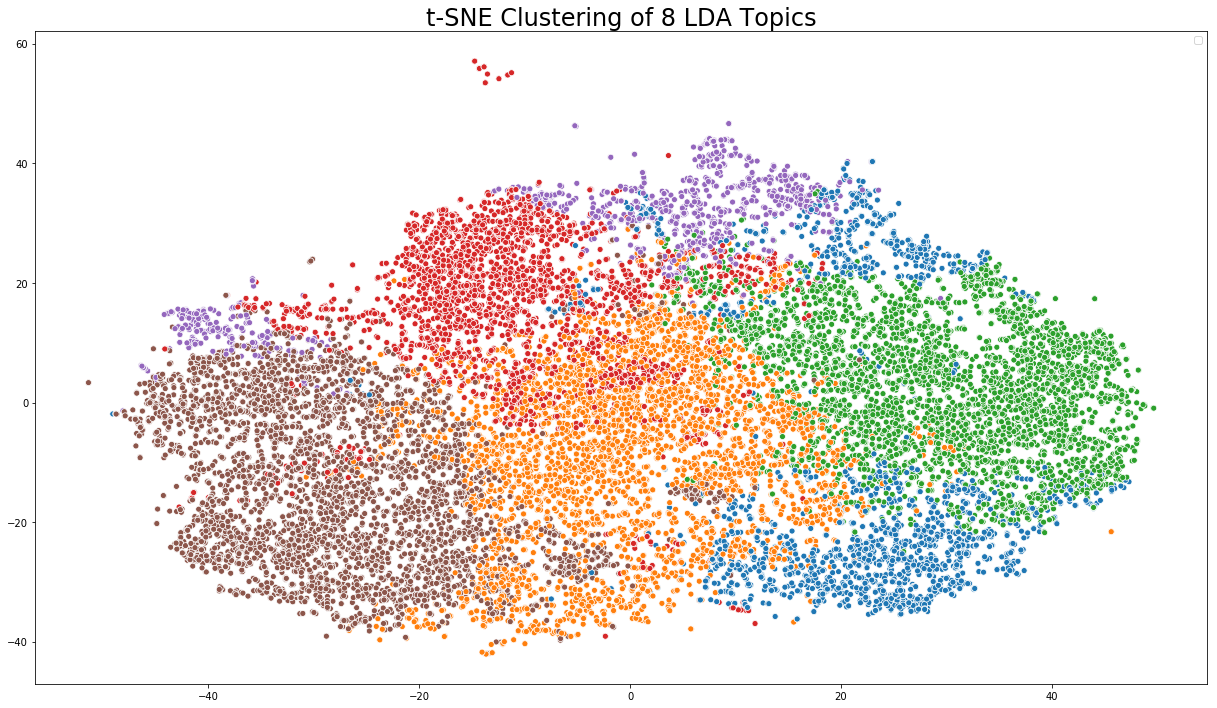

In [49]:
from sklearn.manifold import TSNE
import matplotlib.colors as mcolors
# tSNE Dimension Reduction
tsne_model = TSNE(n_components=2, verbose=1, random_state=0, angle=.99, init='pca');
tsne_KM = tsne_model.fit_transform(X3);
# plot
plt.figure(figsize= (21, 12))
plt.title("t-SNE Clustering of 8 LDA Topics", fontsize= 24)
sns.set_style('whitegrid')
mycolors = np.array([color for name, color in mcolors.TABLEAU_COLORS.items()])
sns.scatterplot(x=tsne_KM[:,0], y=tsne_KM[:,1], hue=mycolors[assigned_clusters])
plt.legend("")
plt.show()

## Assigning Clusters to the text

In [0]:
df['clusters']= assigned_clusters

In [56]:
df[['clean_text', 'clusters']].head(10)

,clean_text,clusters
0,anyone know one become educated art repairing ...,1
1,completed would dispose channel going play sou...,3
2,excuse frequent question checked several faqs ...,5
3,excuse macs got cpu,5
4,okay dont use much would like keep working cor...,5
5,increase memory plus se im sure since havent s...,0
6,thanks enlightening post technical note deskto...,5
7,need add message major problem hands rodime se...,5
8,used live se marked roms go solution person wa...,3
9,yes points really big holes fairly clear stuff...,3
